# Fresh training questions, a minimal targeted seed dose, and constant LR

`08.5`'s 9B-critic run (`ppo-mlx-qwen3.5-9b-l24-n32-lr1e6-err0-delta-s0`: `Qwen3.5-0.8B` policy, frozen `Qwen3.5-9B` critic at layer 24, 32 questions per step, `err0` scoring, `delta` call credit, `lr = 1e-6` annealed to 0 at 400, stopped at 300) lifted the mean of the four held-out probes from `0.566` to **`0.787`** (`err0`: `0.475` → `0.735`). Continuing that run from step 300 to 400 at constant `lr = 1e-6` on `train_units` (`08.5_mlx_stack_data/train_units.jsonl`: `06`'s hard-unit questions repeated ×3 / ×2) nudged the four-probe mean to `0.800`, while `holdout_shift` fell `0.758` → `0.722`: repeating the same 1,200 questions overfit the training phrasing.

This notebook tests whether **fresh questions**, **a minimal targeted seed dose** on the units `07`'s seed never converts right, and **constant `lr = 1e-6` from step 0** lift held-out accuracy above `08.5 @ 300` without losing `holdout_shift`:

| setting | `08.5` (9B critic @ 300) | `09` (`09_fresh_questions`) |
|---|---|---|
| training questions | `06`'s `train` (1,200 questions; ~8 passes by step 300) | `train_all` = `train` + `train2` (3,599 questions, no repeats; ~3.6 passes by step 400) |
| new split `train2` | — | 2,399 questions (seed 505; 40% level-2 units vs 25% in `train`; two `train2`-only sentences per limit, disjoint from `holdout_shift`) |
| seed | `07`'s `seed-n200-r100` (300 episodes) | `seed-09-k2` (316 episodes: `07`'s 300 + `dose_k2.jsonl`, 2 `train2` episodes for each of 8 dead `(param, unit)` pairs) |
| actor learning rate | `1e-6` annealed linearly toward 0 at step 400 (`stop_at = 300`) | constant `1e-6` (`lr_anneal = 0`), 400 steps |
| stack | MLX (`--trainer mlx`) or PyTorch (`--trainer torch`) | identical `09_fresh_questions.py` + `09_fresh_questions_ppo_run.sh` (MLX on macOS, PyTorch on CUDA) |

In [1]:
import importlib.util, json, random, sys
from collections import Counter
from pathlib import Path

HERE = Path.cwd() if (Path.cwd() / "09_fresh_questions.py").exists() else Path("experiments/notebooks/smoke_test35")
sys.argv = ["09_fresh_questions.py"]
spec = importlib.util.spec_from_file_location("pc09", HERE / "09_fresh_questions.py")
pc = importlib.util.module_from_spec(spec)
sys.modules["pc09"] = pc
spec.loader.exec_module(pc)

RUNS09 = pc.RUNS
RUNS085 = HERE / "08.5_mlx_stack_runs"
RUNS08 = HERE / "08_prover_critic_runs"
SEED09 = RUNS09 / "seed-09-k2"
PPO09 = RUNS09 / "ppo-mlx-qwen3.5-9b-l24-n32-lr1e6c-err0-delta-seed09k2-trainall-s0"
PPO085_9B = RUNS085 / "ppo-mlx-qwen3.5-9b-l24-n32-lr1e6-err0-delta-s0"
PPO085_CONT = RUNS085 / "ppo-mlx-qwen3.5-9b-l24-n32-lr1e6-err0-delta-s0-from300-const-units"


def rows_of(path):
    return [json.loads(line) for line in Path(path).read_text().splitlines() if line.strip()]


def jload(path):
    path = Path(path)
    return json.loads(path.read_text()) if path.exists() else None


chk = jload(HERE / "09_fresh_questions_checks.json")
hard_units = {"LMH", "LMH/bar", "ft2", "t/h", "MGD", "F"}
def hard_share(cases):
    def has_hard(c):
        us = {v.get("unit") for v in c["inputs"].values()}
        for pt in c["points"]:
            us |= {v.get("unit") for v in (pt.get("inputs") or {}).values()}
        return bool(us & hard_units)
    return sum(has_hard(c) for c in cases) / len(cases)

tr1, tr2, tr_all = pc.load_split("train"), pc.load_split("train2"), pc.load_split("train_all")
print(f"train: {len(tr1)} questions (hard-unit share {hard_share(tr1):.1%}) | "
      f"train2: {len(tr2)} questions (hard-unit share {hard_share(tr2):.1%}) | train_all: {len(tr_all)}")
print(f"duplicate prompts across all 5 splits: {chk['duplicate_prompts']} | "
      f"max cross-split scenario overlap: {max(chk['cross_split_scenarios'].values())}")
print(f"benchmark decontamination: 8-gram hits = {chk['decontamination']['prompts_with_any_8gram']}, "
      f"scenario collisions = {chk['decontamination']['cases_reusing_a_benchmark_scenario']}")
print("train2 constraint sentence banks:", chk["constraint_sentences"]["train2"])
for k in (2, 4, 8):
    ds = rows_of(pc.OWN_DATA / f"dose_k{k}.jsonl")
    print(f"  dose_k{k}.jsonl: {len(ds)} episodes ({sum('slip' in r for r in ds)} recovery + {sum('slip' not in r for r in ds)} reference)")

train: 1200 questions (hard-unit share 19.4%) | train2: 2399 questions (hard-unit share 31.4%) | train_all: 3599
duplicate prompts across all 5 splits: 0 | max cross-split scenario overlap: 0
benchmark decontamination: 8-gram hits = 0, scenario collisions = 0
train2 constraint sentence banks: {'shared': 2607, 'extra': 1028, 'extra2': 2045}
  dose_k2.jsonl: 16 episodes (6 recovery + 10 reference)
  dose_k4.jsonl: 32 episodes (12 recovery + 20 reference)
  dose_k8.jsonl: 64 episodes (24 recovery + 40 reference)


## The seed: `07`'s recipe + `k = 2` targeted episodes

In `07`'s seed (`seed-n200-r100`), eight `(parameter, unit)` pairs were converted right in ≤ 6% of its 800 warm-up episodes at `T = 1`: `feed_flow_mass_kg_s [t/h]` (0/52), `feed_flow_m3_s [m3/h]` (0/11), `A_comp [LMH/bar]` (1/63), `B_comp [LMH]` (1/52), `feed_temperature_c [F]` (2/72), `feed_flow_mass_kg_s [kg/h]` (2/48), `membrane_area_m2 [ft2]` (3/70), and `feed_tds_g_L [mg/L]` (3/49). Following `06` and `07`, the seed takes the smallest dose that makes the target behavior alive on `dev` at `T = 1` (`k = 2` episodes per target unit = 16 `train2` episodes mixed into `07`'s 300-episode recipe, 1 epoch at `lr = 1e-4`, LoRA `r = 16`), leaving the learning to PPO.

In [2]:
TAGS = ["test-T0-n120-stop", "holdout_shift-T0-stop", "dev-T0-stop-forced", "dev-T1-n120-stop"]
ERR_RESULT, OK_RESULT = '{"error": "recorded error"}', '{"ok": true}'
CASES = {c["id"]: c for s in ("test", "holdout_shift", "dev") for c in pc.load_split(s)}


def score_probe_dir(d):
    out = {}
    for tag in TAGS:
        f = d / f"{tag}.episodes.jsonl"
        if not f.exists():
            return None
        eps = rows_of(f)
        d1, d0 = [], []
        for e in eps:
            calls = [{"name": c["name"], "arguments": c["arguments"], "turn": c.get("turn"),
                      "result": ERR_RESULT if c.get("error") else OK_RESULT} for c in e["calls"]]
            case = CASES[e["id"]]
            pc.ERR_CALL_CREDIT = True
            t1 = pc.score(case, calls, e["final_text"])["total"]
            pc.ERR_CALL_CREDIT = False
            t0 = pc.score(case, calls, e["final_text"])["total"]
            assert abs(t1 - e["score"]["total"]) <= 1e-9
            d1.append((e["id"], t1))
            d0.append((e["id"], t0))
        pc.ERR_CALL_CREDIT = True
        out[tag] = {"default": sum(v for _, v in d1) / len(d1), "err0": sum(v for _, v in d0) / len(d0),
                    "by_id": dict(d1), "by_id_err0": dict(d0), "eps": eps}
    out["mean4_default"] = sum(out[t]["default"] for t in TAGS) / 4
    out["mean4_err0"] = sum(out[t]["err0"] for t in TAGS) / 4
    return out


seed07_dir = RUNS08 / "mlx-probes" / "seed-n200-r100"
seed09_dir = SEED09 / "probes-step0"
print(f"{'seed':18s}  {'test':13s}  {'holdout_shift':13s}  {'dev forced':13s}  {'dev T=1':13s}  {'mean4':13s}")
for label, d in (("07 seed (300)", seed07_dir), ("seed-09-k2 (316)", seed09_dir)):
    s = score_probe_dir(d)
    if s:
        cols = [f"{s[t]['default']:.3f}/{s[t]['err0']:.3f}" for t in TAGS] + [f"{s['mean4_default']:.3f}/{s['mean4_err0']:.3f}"]
        print(f"{label:18s}  " + "  ".join(f"{c:13s}" for c in cols))

seed                test           holdout_shift  dev forced     dev T=1        mean4        
07 seed (300)       0.564/0.489    0.516/0.447    0.688/0.545    0.496/0.419    0.566/0.475  
seed-09-k2 (316)    0.561/0.490    0.502/0.429    0.697/0.553    0.405/0.331    0.541/0.450  


## PPO: 400 steps at constant `lr = 1e-6` on `train_all`

From `seed-09-k2`, PPO runs 400 steps with 32 questions per step (`train_all`), `Qwen3.5-9B` critic at layer 24 (`ridge = 1.0`, `l2 = 0.1`), `err0` scoring, `delta` call credit, turn-level GAE (`λ = 0.95`), `KL = 0.01`, 4 minibatches × 4 epochs, global grad-norm clip `0.5`, and constant `lr = 1e-6` (`lr_anneal = 0`). Greedy `dev` evaluations (120 questions) dip transiently when greedy decoding repeats `convert_units` to the 3,072-token cap (steps 40, 140, 300, 360) and recover on the next evaluation without intervention, reaching **`0.809`** (`err0`) at step 400 (`best = last`).

09 greedy dev evaluations (120 questions, err0):
  step   0: reward 0.438  decision 0.483  evidence 0.467  truncated 0.050  recovered|err 0.461
  step  20: reward 0.438  decision 0.483  evidence 0.467  truncated 0.050  recovered|err 0.461
  step  40: reward 0.301  decision 0.317  evidence 0.267  truncated 0.475  recovered|err 0.294
  step  60: reward 0.517  decision 0.583  evidence 0.525  truncated 0.067  recovered|err 0.514
  step  80: reward 0.540  decision 0.583  evidence 0.558  truncated 0.075  recovered|err 0.540
  step 100: reward 0.539  decision 0.608  evidence 0.542  truncated 0.067  recovered|err 0.543
  step 120: reward 0.576  decision 0.633  evidence 0.608  truncated 0.142  recovered|err 0.587
  step 140: reward 0.515  decision 0.558  evidence 0.533  truncated 0.308  recovered|err 0.658
  step 160: reward 0.610  decision 0.667  evidence 0.650  truncated 0.108  recovered|err 0.682
  step 180: reward 0.615  decision 0.675  evidence 0.650  truncated 0.108  recovered|err 0.661
 

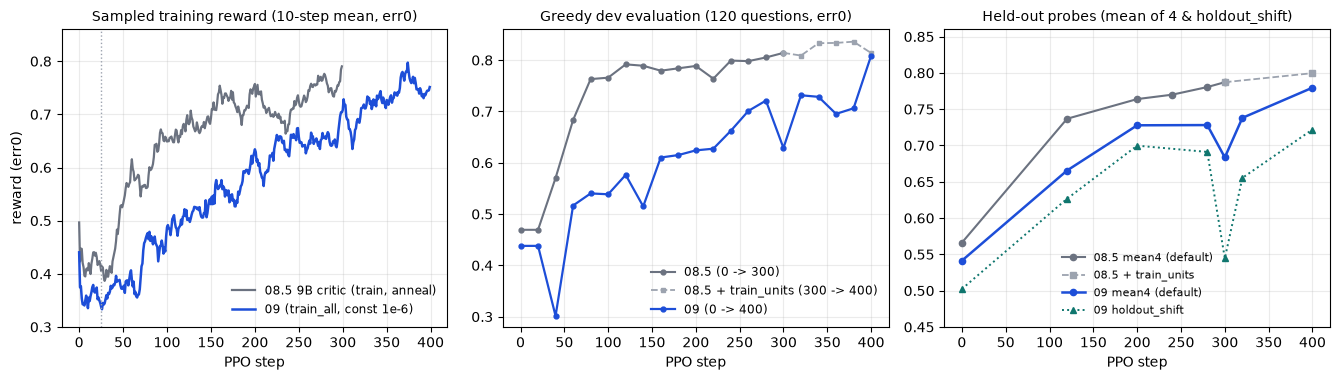

In [3]:
import matplotlib.pyplot as plt


def rolling(xs, k=10):
    return [sum(xs[max(0, i - k + 1): i + 1]) / len(xs[max(0, i - k + 1): i + 1]) for i in range(len(xs))]


m09, ev09 = rows_of(PPO09 / "metrics.jsonl"), rows_of(PPO09 / "eval.jsonl")
m85, ev85 = rows_of(PPO085_9B / "metrics.jsonl"), rows_of(PPO085_9B / "eval.jsonl")
ev85c = rows_of(PPO085_CONT / "eval.jsonl")

print("09 greedy dev evaluations (120 questions, err0):")
for r in ev09:
    trunc = r.get("truncated", 0.0)
    rec = (r.get("recovery") or {}).get("recovered_given_error")
    rec_s = "  -  " if rec is None else f"{rec:.3f}"
    print(f"  step {r['step']:3d}: reward {r['reward']:.3f}  decision {r['decision_correct']:.3f}  "
          f"evidence {r['evidence']:.3f}  truncated {trunc:.3f}  recovered|err {rec_s}")

probe_steps_09 = [0, 120, 200, 280, 300, 320, 400]
p09 = {s: score_probe_dir(SEED09 / "probes-step0" if s == 0 else PPO09 / f"probes-step{s}") for s in probe_steps_09}
probe_steps_85 = [0, 120, 200, 240, 280, 300]
p85 = {s: score_probe_dir(seed07_dir if s == 0 else PPO085_9B / f"probes-step{s}") for s in probe_steps_85}
p85_400 = score_probe_dir(PPO085_CONT / "probes-step400")

fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.9))
ax = axes[0]
ax.plot([r["step"] for r in m85], rolling([r["reward_mean"] for r in m85], 10), color="#6b7280", lw=1.6, label="08.5 9B critic (train, anneal)")
ax.plot([r["step"] for r in m09], rolling([r["reward_mean"] for r in m09], 10), color="#1d4ed8", lw=1.8, label="09 (train_all, const 1e-6)")
ax.axvline(25, color="#9ca3af", ls=":", lw=1)
ax.set_title("Sampled training reward (10-step mean, err0)", fontsize=10)
ax.set_xlabel("PPO step"); ax.set_ylabel("reward (err0)"); ax.set_ylim(0.30, 0.86); ax.grid(alpha=0.25)
ax.legend(frameon=False, fontsize=8.5)

ax = axes[1]
ax.plot([r["step"] for r in ev85], [r["reward"] for r in ev85], "o-", color="#6b7280", ms=3.5, lw=1.5, label="08.5 (0 -> 300)")
ax.plot([r["step"] for r in ev85c if r["step"] >= 300], [r["reward"] for r in ev85c if r["step"] >= 300],
        "s--", color="#9ca3af", ms=3.5, lw=1.3, label="08.5 + train_units (300 -> 400)")
ax.plot([r["step"] for r in ev09], [r["reward"] for r in ev09], "o-", color="#1d4ed8", ms=3.5, lw=1.6, label="09 (0 -> 400)")
ax.set_title("Greedy dev evaluation (120 questions, err0)", fontsize=10)
ax.set_xlabel("PPO step"); ax.set_ylim(0.28, 0.86); ax.grid(alpha=0.25)
ax.legend(frameon=False, fontsize=8.5)

ax = axes[2]
ax.plot(probe_steps_85, [p85[s]["mean4_default"] for s in probe_steps_85], "o-", color="#6b7280", ms=4.5, lw=1.5, label="08.5 mean4 (default)")
ax.plot([300, 400], [p85[300]["mean4_default"], p85_400["mean4_default"]], "s--", color="#9ca3af", ms=4.5, lw=1.3, label="08.5 + train_units")
ax.plot(probe_steps_09, [p09[s]["mean4_default"] for s in probe_steps_09], "o-", color="#1d4ed8", ms=4.5, lw=1.8, label="09 mean4 (default)")
ax.plot(probe_steps_09, [p09[s]["holdout_shift-T0-stop"]["default"] for s in probe_steps_09], "^:", color="#0f766e", ms=4, lw=1.4, label="09 holdout_shift")
ax.set_title("Held-out probes (mean of 4 & holdout_shift)", fontsize=10)
ax.set_xlabel("PPO step"); ax.set_ylim(0.45, 0.86); ax.grid(alpha=0.25)
ax.legend(frameon=False, fontsize=8.2)

fig.tight_layout()
fig.savefig(HERE / "09_fresh_questions_curves.png", dpi=160)
plt.show()

## Held out: steps 0 → 400 against `08.5 @ 300`

Every checkpoint is probed on the same four evaluations (`09_fresh_questions_eval_heldout.sh`) and scored under both `default` (`03`–`08`'s reward) and `err0` (rejected simulator calls earn zero call credit and count as no evidence).

In [4]:
def paired_bootstrap_ci(map_a, map_b, n_boot=4000, seed=0):
    ids = sorted(set(map_a) & set(map_b))
    diffs = [map_a[i] - map_b[i] for i in ids]
    rng = random.Random(seed)
    n = len(diffs)
    boots = sorted(sum(diffs[rng.randrange(n)] for _ in range(n)) / n for _ in range(n_boot))
    return sum(diffs) / n, boots[int(0.025 * n_boot)], boots[int(0.975 * n_boot)]


print(f"{'checkpoint':22s}  {'test':13s}  {'holdout_shift':13s}  {'dev forced':13s}  {'dev T=1':13s}  {'mean4':13s}")
rows_table = [(f"09 step {s}", p09[s]) for s in probe_steps_09] + [
    ("08.5 9B @ 300", p85[300]),
    ("08.5 + units @ 400", p85_400),
]
for label, s in rows_table:
    cols = [f"{s[t]['default']:.3f}/{s[t]['err0']:.3f}" for t in TAGS] + [f"{s['mean4_default']:.3f}/{s['mean4_err0']:.3f}"]
    print(f"{label:22s}  " + "  ".join(f"{c:13s}" for c in cols))

print("\nPaired differences by question (default scoring, 95% bootstrap CI):")
comparisons = [
    ("09 @ 120 - seed-09-k2", p09[120], p09[0]),
    ("09 @ 400 - seed-09-k2", p09[400], p09[0]),
    ("09 @ 400 - 09 @ 280", p09[400], p09[280]),
    ("09 @ 400 - 09 @ 320", p09[400], p09[320]),
    ("09 @ 400 - 08.5 @ 300", p09[400], p85[300]),
]
for name, a, b in comparisons:
    parts = []
    for t, short in zip(TAGS, ("test", "holdout_shift", "dev forced", "dev T=1")):
        mu, lo, hi = paired_bootstrap_ci(a[t]["by_id"], b[t]["by_id"])
        parts.append(f"{short} {mu:+.3f} [{lo:+.3f}, {hi:+.3f}]")
    print(f"  {name:24s}: " + "; ".join(parts))

print("\nFirst-call unit error rate on dev T=1 vs forced-slip recovery (dev forced):")
for s in probe_steps_09:
    eps_t1 = p09[s]["dev-T1-n120-stop"]["eps"]
    sims = [[c for c in e["calls"] if c.get("name") == CASES[e["id"]]["tool"] and isinstance(c.get("arguments"), dict)]
            for e in eps_t1]
    sims = [x for x in sims if x]
    first_err = sum(bool(x[0].get("error")) for x in sims) / len(sims)
    forced_r = p09[s]["dev-T0-stop-forced"]["default"]
    print(f"  step {s:3d}: dev T=1 first simulate call errs {first_err:.1%} | dev forced reward {forced_r:.3f}")

checkpoint              test           holdout_shift  dev forced     dev T=1        mean4        
09 step 0               0.561/0.490    0.502/0.429    0.697/0.553    0.405/0.331    0.541/0.450  
09 step 120             0.681/0.626    0.627/0.575    0.764/0.627    0.590/0.520    0.666/0.587  
09 step 200             0.747/0.689    0.700/0.648    0.748/0.609    0.716/0.646    0.728/0.648  
09 step 280             0.760/0.728    0.691/0.653    0.748/0.607    0.713/0.664    0.728/0.663  
09 step 300             0.723/0.707    0.544/0.529    0.763/0.622    0.703/0.665    0.684/0.631  
09 step 320             0.776/0.748    0.655/0.629    0.768/0.628    0.753/0.712    0.738/0.679  
09 step 400             0.861/0.843    0.722/0.702    0.738/0.594    0.797/0.769    0.780/0.727  
08.5 9B @ 300           0.855/0.839    0.758/0.735    0.781/0.645    0.754/0.723    0.787/0.735  
08.5 + units @ 400      0.875/0.858    0.722/0.698    0.783/0.647    0.818/0.780    0.800/0.746  

Paired differences 

  09 @ 400 - seed-09-k2   : test +0.300 [+0.232, +0.368]; holdout_shift +0.220 [+0.155, +0.285]; dev forced +0.041 [-0.002, +0.087]; dev T=1 +0.392 [+0.323, +0.463]


  09 @ 400 - 09 @ 280     : test +0.101 [+0.051, +0.155]; holdout_shift +0.031 [-0.025, +0.088]; dev forced -0.010 [-0.037, +0.015]; dev T=1 +0.085 [+0.033, +0.139]
  09 @ 400 - 09 @ 320     : test +0.085 [+0.027, +0.149]; holdout_shift +0.067 [+0.008, +0.127]; dev forced -0.030 [-0.054, -0.010]; dev T=1 +0.045 [+0.000, +0.092]


  09 @ 400 - 08.5 @ 300   : test +0.006 [-0.042, +0.055]; holdout_shift -0.036 [-0.091, +0.016]; dev forced -0.043 [-0.084, -0.002]; dev T=1 +0.043 [-0.017, +0.103]

First-call unit error rate on dev T=1 vs forced-slip recovery (dev forced):
  step   0: dev T=1 first simulate call errs 56.0% | dev forced reward 0.697
  step 120: dev T=1 first simulate call errs 48.6% | dev forced reward 0.764
  step 200: dev T=1 first simulate call errs 52.1% | dev forced reward 0.748
  step 280: dev T=1 first simulate call errs 34.7% | dev forced reward 0.748
  step 300: dev T=1 first simulate call errs 27.0% | dev forced reward 0.763
  step 320: dev T=1 first simulate call errs 30.2% | dev forced reward 0.768
  step 400: dev T=1 first simulate call errs 18.3% | dev forced reward 0.738


## Summary

1. **Level with `08.5 @ 300`, not above it.** Starting from a slightly lower seed (`0.541` vs `0.566`), `09` climbs **+0.238** across 400 constant-LR steps to **`0.780` / `err0 0.727`** (`test 0.861`, `holdout_shift 0.722`, `dev` forced `0.738`, `dev` T=1 `0.797`), matching `08.5 @ 300` (`0.787` / `0.735`; four-probe mean difference `-0.008`, with `test`, `holdout_shift`, and `dev` T=1 CIs all spanning 0).
2. **Fresh questions prevented `holdout_shift` decay.** Unlike `08.5`'s `300 → 400` continuation on repeated `train` questions (`holdout_shift` `0.758 → 0.722`), `09` sees each of its 3,599 `train_all` questions ~3.6 times over 400 steps (`08.5 @ 300`: ~8 times on 1,200 questions) and reaches its peak on `test`, `holdout_shift`, and `dev` T=1 at step 400 (`400 − 320`: `test` `+0.085`, `holdout_shift` `+0.067`, `dev` T=1 `+0.045`, all significant; step 300's dip is greedy 3,072-token truncation).
3. **Avoidance starved recovery.** As the convert-first route strengthens, first-call simulator errors on `dev` T=1 fall from **56%** (step 0) and **52%** (step 200) to **18%** at step 400. With fewer natural errors in on-policy rollouts, recovery after an error loses training signal: `dev` forced peaks at step 320 (`0.768`) and drops significantly from 320 to 400 (`−0.030`, 95% CI `[−0.053, −0.011]`), accounting for the entire `-0.043` gap against `08.5 @ 300` on `dev` forced.